# Homework 6.2 - Steps 7-8

## Controlled Ambiguous Glyphs and Attention Analysis

This notebook performs the deliberately ambiguous many-to-one experiment required by Homework 6.2.

The construction follows the assignment's information rules:

1. permitted labels are fixed on the **original** glyph sequence first;
2. selected original glyphs are merged afterward;
3. the merge rule is frozen using training-side information only;
4. the same merge is applied to training, validation, and test glyph sequences;
5. the decoder receives only the merged observed symbol;
6. original pre-merge glyph identity is never retained as an input feature.

The selected attention architecture from the bijective experiment is reused unchanged.

## Why the merge must respect nested anchors

Let

$$
A_5
\subseteq
A_{10}
\subseteq
A_{20}
\subseteq
A_{40}
$$

be the nested revealed-anchor sets.

If two original glyphs are merged, they must have the same membership in every anchor set.

Thus a merge group is always either:

- fully revealed at a given anchor level; or
- fully unrevealed at that level.

This prevents one original member of an ambiguous observed glyph from secretly revealing the other.

In [1]:
from pathlib import Path
import json
import math
import random
import time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw6_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw6_2"
MODEL_DIR = DATA_DIR / "ambiguous_models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

manifest = json.loads(
    (
        DATA_DIR
        / "task2_frozen_information_manifest.json"
    ).read_text(
        encoding="utf-8"
    )
)

selection = json.loads(
    (
        DATA_DIR
        / "task6_selected_attention_architecture.json"
    ).read_text(
        encoding="utf-8"
    )
)

SELECTED_CONFIG = selection[
    "selected_config"
]

ANCHOR_LEVELS = ["05", "10", "20", "40"]
K = int(
    manifest["source_vocabulary_size"]
)

SEED = 63867
BATCH_SIZE = 256
MAX_EPOCHS = 8
PATIENCE = 2
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-5
DROPOUT = 0.10

PAIRS_PER_SIGNATURE = 8

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Selected bijective architecture:")
print(json.dumps(SELECTED_CONFIG, indent=2))
print("Device:", DEVICE)

Selected bijective architecture:
{
  "embed_dim": 96,
  "radius": 4,
  "num_heads": 2,
  "num_layers": 1
}
Device: cuda


# Load training and validation information only

The test glyph sequence and hidden answer key remain unopened while the merge rule and ambiguous models are constructed.

In [2]:
def absolute_from_manifest(relative_path):
    return PROJECT_ROOT / relative_path


def pick_column(frame, candidates, label):
    lowered = {
        column.lower(): column
        for column in frame.columns
    }

    for candidate in candidates:
        if candidate.lower() in lowered:
            return lowered[candidate.lower()]

    for column in frame.columns:
        low = column.lower()

        if any(
            candidate.lower() in low
            for candidate in candidates
        ):
            return column

    raise KeyError(
        f"Could not identify {label}. "
        f"Available columns: {list(frame.columns)}"
    )


GLYPH_CANDIDATES = [
    "glyph_id",
    "glyph",
    "glyph_index",
    "token",
]

SOURCE_CANDIDATES = [
    "source_token_id",
    "syllable_id",
    "source_id",
    "token_id",
]


def load_raw_split(split_name):
    frame = pd.read_csv(
        absolute_from_manifest(
            manifest["splits"][
                split_name
            ]
        )
    )

    glyph_col = pick_column(
        frame,
        GLYPH_CANDIDATES,
        "glyph ID",
    )

    return frame[
        glyph_col
    ].to_numpy()


def load_anchor(level):
    frame = pd.read_csv(
        absolute_from_manifest(
            manifest["anchors"][level]
        )
    )

    glyph_col = pick_column(
        frame,
        GLYPH_CANDIDATES,
        "glyph ID",
    )

    source_col = pick_column(
        frame,
        SOURCE_CANDIDATES,
        "source-token ID",
    )

    normalized = frame[
        [
            glyph_col,
            source_col,
        ]
    ].copy()

    normalized.columns = [
        "glyph_id",
        "source_token_id",
    ]

    return normalized


def load_pseudo_map(level):
    return pd.read_csv(
        absolute_from_manifest(
            manifest[
                "pseudo_label_maps"
            ][level]
        )
    )[
        [
            "glyph_id",
            "source_token_id",
        ]
    ]


train_raw = load_raw_split(
    "train"
)

validation_raw = load_raw_split(
    "validation"
)

anchors = {
    level: load_anchor(level)
    for level in ANCHOR_LEVELS
}

pseudo_maps = {
    level: load_pseudo_map(level)
    for level in ANCHOR_LEVELS
}

reference_pseudo = pseudo_maps[
    "20"
]

raw_glyph_ids = np.array(
    sorted(
        reference_pseudo[
            "glyph_id"
        ].unique()
    )
)

raw_source_ids = np.array(
    sorted(
        reference_pseudo[
            "source_token_id"
        ].unique()
    )
)

source_to_index = {
    raw_id: index
    for index, raw_id
    in enumerate(raw_source_ids)
}

index_to_source = {
    index: raw_id
    for raw_id, index
    in source_to_index.items()
}

common_positions = pd.read_csv(
    absolute_from_manifest(
        manifest[
            "common_evaluation_positions"
        ]
    )
)

validation_common_positions = (
    common_positions[
        common_positions["split"]
        == "validation"
    ]["position"]
    .to_numpy(dtype=int)
)

print("Training glyphs:", f"{len(train_raw):,}")
print("Validation glyphs:", f"{len(validation_raw):,}")
print("Test split has not been loaded.")

Training glyphs: 54,082
Validation glyphs: 11,589
Test split has not been loaded.


# Task 7A: define anchor-membership signatures

For an original glyph $$g$$, define its nested-anchor signature

$$
s(g)
=
\left(
\mathbf 1_{g\in A_5},
\mathbf 1_{g\in A_{10}},
\mathbf 1_{g\in A_{20}},
\mathbf 1_{g\in A_{40}}
\right).
$$

Only glyphs with identical signatures are eligible to be merged.

In [3]:
anchor_sets = {
    level: set(
        anchors[level][
            "glyph_id"
        ].tolist()
    )
    for level in ANCHOR_LEVELS
}


def anchor_signature(glyph_id):
    return tuple(
        glyph_id
        in anchor_sets[level]
        for level in ANCHOR_LEVELS
    )


training_frequency = (
    pd.Series(train_raw)
    .value_counts()
    .to_dict()
)

signature_groups = defaultdict(
    list
)

for glyph_id in raw_glyph_ids:
    signature_groups[
        anchor_signature(
            glyph_id
        )
    ].append(glyph_id)

signature_summary = []

for signature, glyphs in sorted(
    signature_groups.items(),
    key=lambda item: item[0],
):
    signature_summary.append({
        "signature": str(signature),
        "glyph_types": len(glyphs),
        "training_occurrences": int(
            sum(
                training_frequency.get(
                    glyph,
                    0,
                )
                for glyph in glyphs
            )
        ),
    })


signature_summary = pd.DataFrame(
    signature_summary
)

signature_path = (
    DATA_DIR
    / "task7_anchor_signature_summary.csv"
)

signature_summary.to_csv(
    signature_path,
    index=False,
)

print(signature_summary.to_string(index=False))

                   signature  glyph_types  training_occurrences
(False, False, False, False)         1831                 34423
 (False, False, False, True)          611                  8895
  (False, False, True, True)          305                  5683
   (False, True, True, True)          152                  2270
    (True, True, True, True)          153                  2811


# Task 7B: freeze the many-to-one merge rule

Within each signature class, glyphs are ranked by training frequency and paired deterministically.

At most eight pairs are selected from each signature class.

This rule uses:

- training glyph identity and frequency;
- revealed-anchor membership.

It does **not** use hidden plaintext or the true unrevealed map.

In [4]:
merge_pairs = []
pair_counter = 0

for signature, glyphs in sorted(
    signature_groups.items(),
    key=lambda item: item[0],
):
    ordered = sorted(
        glyphs,
        key=lambda glyph: (
            -training_frequency.get(
                glyph,
                0,
            ),
            glyph,
        ),
    )

    usable_pair_count = min(
        PAIRS_PER_SIGNATURE,
        len(ordered) // 2,
    )

    for local_pair in range(
        usable_pair_count
    ):
        first = ordered[
            2 * local_pair
        ]

        second = ordered[
            2 * local_pair + 1
        ]

        merge_pairs.append({
            "merge_group_id": (
                pair_counter
            ),
            "glyph_a": first,
            "glyph_b": second,
            "anchor_signature": (
                str(signature)
            ),
            "glyph_a_train_frequency": int(
                training_frequency.get(
                    first,
                    0,
                )
            ),
            "glyph_b_train_frequency": int(
                training_frequency.get(
                    second,
                    0,
                )
            ),
        })

        pair_counter += 1


merge_pairs_frame = pd.DataFrame(
    merge_pairs
)

if len(
    set(
        merge_pairs_frame[
            "glyph_a"
        ].tolist()
        + merge_pairs_frame[
            "glyph_b"
        ].tolist()
    )
) != 2 * len(
    merge_pairs_frame
):
    raise RuntimeError(
        "A glyph was used in more than one merge pair."
    )

merge_pairs_path = (
    DATA_DIR
    / "task7_merge_pairs.csv"
)

merge_pairs_frame.to_csv(
    merge_pairs_path,
    index=False,
)

print(
    "Frozen merge pairs:",
    len(merge_pairs_frame),
)

print(
    merge_pairs_frame.head(
        20
    ).to_string(
        index=False
    )
)

Frozen merge pairs: 40
 merge_group_id  glyph_a  glyph_b             anchor_signature  glyph_a_train_frequency  glyph_b_train_frequency
              0     2748     2196 (False, False, False, False)                     2042                     1373
              1       35     2694 (False, False, False, False)                     1271                     1215
              2     1145     2568 (False, False, False, False)                      941                      932
              3     1256      427 (False, False, False, False)                      846                      601
              4     2608     2450 (False, False, False, False)                      594                      559
              5     2232      236 (False, False, False, False)                      548                      518
              6     2716     3042 (False, False, False, False)                      467                      456
              7     2132     2009 (False, False, False, False)           

## Convert original glyphs to merged observed-symbol indices

Every original glyph belongs to exactly one observed symbol:

- an unmerged glyph maps to its own observed symbol;
- the two members of a merge pair map to one common observed symbol.

The resulting neural input contains only the observed-symbol index.

The original glyph ID is retained separately only for label construction and final evaluation; it is **not** a model input.

In [5]:
original_to_group = {}
group_members = {}

for row in merge_pairs_frame.itertuples():
    key = (
        "merged",
        int(row.merge_group_id),
    )

    members = [
        row.glyph_a,
        row.glyph_b,
    ]

    group_members[key] = (
        members
    )

    for glyph in members:
        original_to_group[
            glyph
        ] = key


for glyph in raw_glyph_ids:
    if glyph not in original_to_group:
        key = (
            "single",
            glyph,
        )

        group_members[key] = [
            glyph
        ]

        original_to_group[
            glyph
        ] = key


ordered_groups = sorted(
    group_members.keys(),
    key=lambda key: (
        0 if key[0] == "single" else 1,
        str(key[1]),
    ),
)

group_to_observed_index = {
    key: index
    for index, key
    in enumerate(ordered_groups)
}

observed_index_to_group = {
    index: key
    for key, index
    in group_to_observed_index.items()
}

original_to_observed_index = {
    glyph: group_to_observed_index[
        original_to_group[glyph]
    ]
    for glyph in raw_glyph_ids
}

AMBIGUOUS_VOCAB_SIZE = len(
    ordered_groups
)

merged_original_glyphs = set(
    merge_pairs_frame[
        "glyph_a"
    ].tolist()
    + merge_pairs_frame[
        "glyph_b"
    ].tolist()
)


def apply_merge(raw_sequence):
    return np.array(
        [
            original_to_observed_index[
                glyph
            ]
            for glyph in raw_sequence
        ],
        dtype=np.int64,
    )


train_observed = apply_merge(
    train_raw
)

validation_observed = apply_merge(
    validation_raw
)

print(
    "Original glyph vocabulary:",
    K,
)

print(
    "Merged observed vocabulary:",
    AMBIGUOUS_VOCAB_SIZE,
)

print(
    "Original glyphs participating in merges:",
    len(merged_original_glyphs),
)

Original glyph vocabulary: 3052
Merged observed vocabulary: 3012
Original glyphs participating in merges: 80


# Labels are fixed before merging

For each anchor level, the training and validation target label at an occurrence is obtained from the original glyph's carried-over Homework 5.1 pseudo-label map.

The target label is therefore fixed **before** the observed glyph is replaced by its merged symbol.

In [6]:
def pseudo_label_sequence(
    raw_sequence,
    level,
):
    mapping = dict(
        zip(
            pseudo_maps[level][
                "glyph_id"
            ],
            pseudo_maps[level][
                "source_token_id"
            ],
        )
    )

    return np.array(
        [
            source_to_index[
                mapping[glyph]
            ]
            for glyph
            in raw_sequence
        ],
        dtype=np.int64,
    )


train_labels = {
    level: pseudo_label_sequence(
        train_raw,
        level,
    )
    for level in ANCHOR_LEVELS
}

validation_labels = {
    level: pseudo_label_sequence(
        validation_raw,
        level,
    )
    for level in ANCHOR_LEVELS
}

# Decoder definitions

The ambiguous experiment uses the exact selected bijective attention architecture.

The matched MLP baseline again uses the same context, same labels, same embedding dimension, and a comparable parameter count.

In [7]:
class CenteredWindowDataset(Dataset):
    def __init__(
        self,
        observed_sequence,
        label_sequence,
        radius,
        centers=None,
    ):
        self.observed = np.asarray(
            observed_sequence,
            dtype=np.int64,
        )

        self.labels = np.asarray(
            label_sequence,
            dtype=np.int64,
        )

        self.radius = int(radius)

        if centers is None:
            centers = np.arange(
                self.radius,
                len(self.observed)
                - self.radius,
                dtype=int,
            )

        centers = np.asarray(
            centers,
            dtype=int,
        )

        valid = (
            (centers >= self.radius)
            & (
                centers
                < len(self.observed)
                - self.radius
            )
        )

        self.centers = centers[
            valid
        ]

    def __len__(self):
        return len(self.centers)

    def __getitem__(self, item):
        center = int(
            self.centers[item]
        )

        window = self.observed[
            center-self.radius:
            center+self.radius+1
        ]

        label = self.labels[
            center
        ]

        return (
            torch.as_tensor(
                window,
                dtype=torch.long,
            ),
            torch.tensor(
                int(label),
                dtype=torch.long,
            ),
            torch.tensor(
                center,
                dtype=torch.long,
            ),
        )


class AttentionBlock(nn.Module):
    def __init__(
        self,
        embed_dim,
        num_heads,
        dropout,
    ):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(
                embed_dim,
                2 * embed_dim,
            ),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(
                2 * embed_dim,
                embed_dim,
            ),
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(
        self,
        x,
        return_weights=False,
    ):
        attended, weights = (
            self.attention(
                x,
                x,
                x,
                need_weights=True,
                average_attn_weights=False,
            )
        )

        x = self.norm1(
            x
            + self.dropout(
                attended
            )
        )

        x = self.norm2(
            x
            + self.dropout(
                self.feed_forward(x)
            )
        )

        if return_weights:
            return x, weights

        return x


class CenteredAttentionDecoder(nn.Module):
    def __init__(
        self,
        observed_vocab_size,
        source_vocab_size,
        radius,
        embed_dim,
        num_heads,
        num_layers,
        dropout,
    ):
        super().__init__()

        self.radius = int(radius)
        self.window_length = (
            2 * self.radius + 1
        )

        self.glyph_embedding = nn.Embedding(
            observed_vocab_size,
            embed_dim,
        )

        self.position_embedding = nn.Embedding(
            self.window_length,
            embed_dim,
        )

        self.blocks = nn.ModuleList([
            AttentionBlock(
                embed_dim,
                num_heads,
                dropout,
            )
            for _ in range(
                num_layers
            )
        ])

        self.output = nn.Linear(
            embed_dim,
            source_vocab_size,
        )

    def forward(
        self,
        windows,
        return_attention=False,
    ):
        positions = torch.arange(
            windows.shape[1],
            device=windows.device,
        )

        x = (
            self.glyph_embedding(
                windows
            )
            + self.position_embedding(
                positions
            )[None, :, :]
        )

        weights_by_layer = []

        for block in self.blocks:
            if return_attention:
                x, weights = block(
                    x,
                    return_weights=True,
                )

                weights_by_layer.append(
                    weights
                )

            else:
                x = block(x)

        logits = self.output(
            x[:, self.radius, :]
        )

        if return_attention:
            return logits, weights_by_layer

        return logits


class CenteredMLPDecoder(nn.Module):
    def __init__(
        self,
        observed_vocab_size,
        source_vocab_size,
        radius,
        embed_dim,
        hidden_dim,
        dropout,
    ):
        super().__init__()

        self.radius = int(radius)
        self.window_length = (
            2 * self.radius + 1
        )

        self.embedding = nn.Embedding(
            observed_vocab_size,
            embed_dim,
        )

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                self.window_length
                * embed_dim,
                hidden_dim,
            ),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(
                hidden_dim,
                source_vocab_size,
            ),
        )

    def forward(self, windows):
        return self.network(
            self.embedding(
                windows
            )
        )


def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


def matched_hidden_dim(
    target_parameters,
    radius,
    embed_dim,
):
    best = None
    best_difference = None

    for hidden_dim in range(
        16,
        513,
        8,
    ):
        candidate = CenteredMLPDecoder(
            observed_vocab_size=(
                AMBIGUOUS_VOCAB_SIZE
            ),
            source_vocab_size=K,
            radius=radius,
            embed_dim=embed_dim,
            hidden_dim=hidden_dim,
            dropout=DROPOUT,
        )

        difference = abs(
            count_parameters(
                candidate
            )
            - target_parameters
        )

        if (
            best_difference is None
            or difference
            < best_difference
        ):
            best = hidden_dim
            best_difference = difference

    return best

# Train attention and MLP models for each anchor level

No test glyphs or hidden true labels are used during this stage.

In [8]:
def evaluate_pseudo(
    model,
    loader,
):
    model.eval()

    loss_fn = nn.CrossEntropyLoss(
        reduction="sum"
    )

    total_loss = 0.0
    total_correct = 0
    total = 0

    with torch.no_grad():
        for windows, labels, _ in loader:
            windows = windows.to(
                DEVICE
            )

            labels = labels.to(
                DEVICE
            )

            logits = model(
                windows
            )

            total_loss += float(
                loss_fn(
                    logits,
                    labels,
                ).item()
            )

            total_correct += int(
                (
                    logits.argmax(
                        dim=1
                    )
                    == labels
                ).sum().item()
            )

            total += int(
                labels.shape[0]
            )

    return {
        "nll": (
            total_loss / total
        ),
        "accuracy": (
            total_correct / total
        ),
    }


def train_model(
    model,
    train_dataset,
    validation_dataset,
    run_seed,
):
    random.seed(run_seed)
    np.random.seed(run_seed)
    torch.manual_seed(run_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            run_seed
        )

    model = model.to(
        DEVICE
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    loss_fn = (
        nn.CrossEntropyLoss()
    )

    best_nll = float("inf")
    best_accuracy = 0.0
    best_epoch = None
    best_state = None
    stale = 0

    for epoch in range(
        1,
        MAX_EPOCHS + 1,
    ):
        model.train()

        for windows, labels, _ in train_loader:
            windows = windows.to(
                DEVICE
            )

            labels = labels.to(
                DEVICE
            )

            optimizer.zero_grad()

            loss = loss_fn(
                model(windows),
                labels,
            )

            loss.backward()
            optimizer.step()

        metrics = evaluate_pseudo(
            model,
            validation_loader,
        )

        if (
            metrics["nll"]
            < best_nll - 1e-6
        ):
            best_nll = (
                metrics["nll"]
            )

            best_accuracy = (
                metrics["accuracy"]
            )

            best_epoch = epoch

            best_state = {
                key: value.detach()
                .cpu()
                .clone()
                for key, value
                in model.state_dict().items()
            }

            stale = 0

        else:
            stale += 1

        if stale >= PATIENCE:
            break

    model.load_state_dict(
        best_state
    )

    return {
        "model": model,
        "state_dict": best_state,
        "validation_nll": (
            best_nll
        ),
        "validation_accuracy": (
            best_accuracy
        ),
        "best_epoch": (
            best_epoch
        ),
        "parameters": (
            count_parameters(model)
        ),
    }


selected_radius = int(
    SELECTED_CONFIG[
        "radius"
    ]
)

selected_embed_dim = int(
    SELECTED_CONFIG[
        "embed_dim"
    ]
)

attention_template = (
    CenteredAttentionDecoder(
        observed_vocab_size=(
            AMBIGUOUS_VOCAB_SIZE
        ),
        source_vocab_size=K,
        radius=selected_radius,
        embed_dim=selected_embed_dim,
        num_heads=int(
            SELECTED_CONFIG[
                "num_heads"
            ]
        ),
        num_layers=int(
            SELECTED_CONFIG[
                "num_layers"
            ]
        ),
        dropout=DROPOUT,
    )
)

attention_parameter_target = (
    count_parameters(
        attention_template
    )
)

baseline_hidden_dim = (
    matched_hidden_dim(
        attention_parameter_target,
        selected_radius,
        selected_embed_dim,
    )
)

training_records = []

for level_index, level in enumerate(
    ANCHOR_LEVELS
):
    train_dataset = CenteredWindowDataset(
        train_observed,
        train_labels[level],
        radius=selected_radius,
    )

    validation_dataset = (
        CenteredWindowDataset(
            validation_observed,
            validation_labels[level],
            radius=selected_radius,
            centers=validation_common_positions,
        )
    )

    attention_model = (
        CenteredAttentionDecoder(
            observed_vocab_size=(
                AMBIGUOUS_VOCAB_SIZE
            ),
            source_vocab_size=K,
            radius=selected_radius,
            embed_dim=selected_embed_dim,
            num_heads=int(
                SELECTED_CONFIG[
                    "num_heads"
                ]
            ),
            num_layers=int(
                SELECTED_CONFIG[
                    "num_layers"
                ]
            ),
            dropout=DROPOUT,
        )
    )

    mlp_model = (
        CenteredMLPDecoder(
            observed_vocab_size=(
                AMBIGUOUS_VOCAB_SIZE
            ),
            source_vocab_size=K,
            radius=selected_radius,
            embed_dim=selected_embed_dim,
            hidden_dim=baseline_hidden_dim,
            dropout=DROPOUT,
        )
    )

    for model_name, model in [
        (
            "attention",
            attention_model,
        ),
        (
            "mlp_baseline",
            mlp_model,
        ),
    ]:
        result = train_model(
            model,
            train_dataset,
            validation_dataset,
            run_seed=(
                SEED
                + 100
                + 10 * level_index
                + (
                    0
                    if model_name
                    == "attention"
                    else 1
                )
            ),
        )

        checkpoint_path = (
            MODEL_DIR
            / (
                f"{model_name}_"
                f"ambiguous_anchors_"
                f"{level}.pt"
            )
        )

        torch.save(
            {
                "state_dict": (
                    result[
                        "state_dict"
                    ]
                ),
                "model_name": (
                    model_name
                ),
                "anchor_level": (
                    level
                ),
                "selected_config": (
                    SELECTED_CONFIG
                ),
                "observed_vocab_size": (
                    AMBIGUOUS_VOCAB_SIZE
                ),
                "mlp_hidden_dim": (
                    baseline_hidden_dim
                ),
                "parameter_count": (
                    result[
                        "parameters"
                    ]
                ),
            },
            checkpoint_path,
        )

        training_records.append({
            "anchor_level": (
                int(level)
            ),
            "model": model_name,
            "validation_nll": (
                result[
                    "validation_nll"
                ]
            ),
            "validation_accuracy": (
                result[
                    "validation_accuracy"
                ]
            ),
            "best_epoch": (
                result[
                    "best_epoch"
                ]
            ),
            "trainable_parameters": (
                result[
                    "parameters"
                ]
            ),
            "checkpoint": str(
                checkpoint_path.relative_to(
                    PROJECT_ROOT
                )
            ),
        })


ambiguous_training_manifest = (
    pd.DataFrame(
        training_records
    )
)

training_manifest_path = (
    DATA_DIR
    / "task7_ambiguous_training_manifest.csv"
)

ambiguous_training_manifest.to_csv(
    training_manifest_path,
    index=False,
)

print(
    ambiguous_training_manifest
    .sort_values(
        [
            "anchor_level",
            "model",
        ]
    )
    .to_string(
        index=False
    )
)

 anchor_level        model  validation_nll  validation_accuracy  best_epoch  trainable_parameters                                                       checkpoint
            5    attention        0.372307             0.908281           6                660844    data\hw6_2\ambiguous_models\attention_ambiguous_anchors_05.pt
            5 mlp_baseline        0.494156             0.901878           4                668236 data\hw6_2\ambiguous_models\mlp_baseline_ambiguous_anchors_05.pt
           10    attention        0.388472             0.903781           7                660844    data\hw6_2\ambiguous_models\attention_ambiguous_anchors_10.pt
           10 mlp_baseline        0.501522             0.902397           4                668236 data\hw6_2\ambiguous_models\mlp_baseline_ambiguous_anchors_10.pt
           20    attention        0.362937             0.905252           5                660844    data\hw6_2\ambiguous_models\attention_ambiguous_anchors_20.pt
           20 mlp_base

# Final ambiguous-glyph evaluation

All ambiguous models and the merge rule are now frozen.

Only now are the test glyph sequence and evaluation-only hidden map loaded.

In [9]:
# ---------------------------
# FINAL EVALUATION BOUNDARY
# ---------------------------

test_raw = load_raw_split(
    "test"
)

test_observed = apply_merge(
    test_raw
)

hidden_map_frame = pd.read_csv(
    absolute_from_manifest(
        manifest[
            "evaluation_only_hidden_map"
        ]
    )
)

hidden_glyph_col = pick_column(
    hidden_map_frame,
    GLYPH_CANDIDATES,
    "hidden-map glyph ID",
)

hidden_source_col = pick_column(
    hidden_map_frame,
    SOURCE_CANDIDATES,
    "hidden-map source-token ID",
)

true_inverse_map = dict(
    zip(
        hidden_map_frame[
            hidden_glyph_col
        ],
        hidden_map_frame[
            hidden_source_col
        ],
    )
)

test_true_raw_source = np.array(
    [
        true_inverse_map[glyph]
        for glyph in test_raw
    ]
)

test_true_labels = np.array(
    [
        source_to_index[
            source_id
        ]
        for source_id
        in test_true_raw_source
    ],
    dtype=np.int64,
)

test_common_positions = (
    common_positions[
        common_positions["split"]
        == "test"
    ]["position"]
    .to_numpy(dtype=int)
)

print("Test glyphs:", f"{len(test_raw):,}")
print(
    "Common test centers:",
    f"{len(test_common_positions):,}",
)

Test glyphs: 11,589
Common test centers: 11,557


In [10]:
def build_ambiguous_model(
    checkpoint_path,
):
    payload = torch.load(
        checkpoint_path,
        map_location=DEVICE,
    )

    if (
        payload["model_name"]
        == "attention"
    ):
        model = (
            CenteredAttentionDecoder(
                observed_vocab_size=(
                    payload[
                        "observed_vocab_size"
                    ]
                ),
                source_vocab_size=K,
                radius=int(
                    payload[
                        "selected_config"
                    ]["radius"]
                ),
                embed_dim=int(
                    payload[
                        "selected_config"
                    ]["embed_dim"]
                ),
                num_heads=int(
                    payload[
                        "selected_config"
                    ]["num_heads"]
                ),
                num_layers=int(
                    payload[
                        "selected_config"
                    ]["num_layers"]
                ),
                dropout=DROPOUT,
            )
        )

    else:
        model = CenteredMLPDecoder(
            observed_vocab_size=(
                payload[
                    "observed_vocab_size"
                ]
            ),
            source_vocab_size=K,
            radius=int(
                payload[
                    "selected_config"
                ]["radius"]
            ),
            embed_dim=int(
                payload[
                    "selected_config"
                ]["embed_dim"]
            ),
            hidden_dim=int(
                payload[
                    "mlp_hidden_dim"
                ]
            ),
            dropout=DROPOUT,
        )

    model.load_state_dict(
        payload["state_dict"]
    )

    model = model.to(
        DEVICE
    )

    model.eval()

    return model, payload


def evaluate_ambiguous_model(
    model,
    level,
):
    dummy_labels = np.zeros(
        len(test_observed),
        dtype=np.int64,
    )

    dataset = CenteredWindowDataset(
        test_observed,
        dummy_labels,
        radius=selected_radius,
        centers=test_common_positions,
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    anchored_set = set(
        anchors[level][
            "glyph_id"
        ].tolist()
    )

    relation_probability_sums = {
        int(row.merge_group_id): (
            np.zeros(
                K,
                dtype=np.float64,
            )
        )
        for row
        in merge_pairs_frame.itertuples()
    }

    relation_counts = {
        int(row.merge_group_id): 0
        for row
        in merge_pairs_frame.itertuples()
    }

    observed_index_to_merge_group = {}

    for row in merge_pairs_frame.itertuples():
        key = (
            "merged",
            int(row.merge_group_id),
        )

        observed_index = (
            group_to_observed_index[
                key
            ]
        )

        observed_index_to_merge_group[
            observed_index
        ] = int(
            row.merge_group_id
        )

    prediction_rows = []

    with torch.no_grad():
        for windows, _, centers_batch in loader:
            windows_device = windows.to(
                DEVICE
            )

            logits = model(
                windows_device
            )

            probabilities = (
                torch.softmax(
                    logits,
                    dim=1,
                )
                .cpu()
                .numpy()
            )

            predicted = np.argmax(
                probabilities,
                axis=1,
            )

            confidence = np.max(
                probabilities,
                axis=1,
            )

            windows_numpy = windows.numpy()

            for row_index, center in enumerate(
                centers_batch.numpy()
            ):
                original_glyph = (
                    test_raw[
                        center
                    ]
                )

                observed_index = int(
                    test_observed[
                        center
                    ]
                )

                is_ambiguous = (
                    original_glyph
                    in merged_original_glyphs
                )

                is_anchored = (
                    original_glyph
                    in anchored_set
                )

                predicted_source = (
                    index_to_source[
                        int(
                            predicted[
                                row_index
                            ]
                        )
                    ]
                )

                truth_source = (
                    test_true_raw_source[
                        center
                    ]
                )

                prediction_rows.append({
                    "position": int(center),
                    "observed_symbol_index": (
                        observed_index
                    ),
                    "original_glyph_id_evaluation_only": (
                        original_glyph
                    ),
                    "true_source_token_id": (
                        truth_source
                    ),
                    "predicted_source_token_id": (
                        predicted_source
                    ),
                    "confidence": float(
                        confidence[
                            row_index
                        ]
                    ),
                    "ambiguous_occurrence": (
                        is_ambiguous
                    ),
                    "anchored_occurrence": (
                        is_anchored
                    ),
                    "correct": (
                        predicted_source
                        == truth_source
                    ),
                })

                if (
                    observed_index
                    in observed_index_to_merge_group
                ):
                    group_id = (
                        observed_index_to_merge_group[
                            observed_index
                        ]
                    )

                    relation_probability_sums[
                        group_id
                    ] += probabilities[
                        row_index
                    ]

                    relation_counts[
                        group_id
                    ] += 1

    predictions = pd.DataFrame(
        prediction_rows
    )

    relation_rows = []

    for row in merge_pairs_frame.itertuples():
        group_id = int(
            row.merge_group_id
        )

        true_relation = {
            true_inverse_map[
                row.glyph_a
            ],
            true_inverse_map[
                row.glyph_b
            ],
        }

        count = relation_counts[
            group_id
        ]

        if count > 0:
            mean_prob = (
                relation_probability_sums[
                    group_id
                ]
                / count
            )

            top_indices = np.argsort(
                mean_prob
            )[-2:][::-1]

            predicted_relation = {
                index_to_source[
                    int(index)
                ]
                for index
                in top_indices
            }

            exact = (
                predicted_relation
                == true_relation
            )

            jaccard = (
                len(
                    predicted_relation
                    & true_relation
                )
                / len(
                    predicted_relation
                    | true_relation
                )
            )

        else:
            predicted_relation = set()
            exact = False
            jaccard = np.nan

        relation_rows.append({
            "merge_group_id": (
                group_id
            ),
            "test_occurrences": (
                count
            ),
            "true_relation": (
                "|".join(
                    map(
                        str,
                        sorted(
                            true_relation
                        ),
                    )
                )
            ),
            "predicted_relation": (
                "|".join(
                    map(
                        str,
                        sorted(
                            predicted_relation
                        ),
                    )
                )
            ),
            "exact_relation_recovery": (
                exact
            ),
            "jaccard": jaccard,
        })

    relation_frame = pd.DataFrame(
        relation_rows
    )

    ambiguous = predictions[
        predictions[
            "ambiguous_occurrence"
        ]
    ]

    revealed_ambiguous = ambiguous[
        ambiguous[
            "anchored_occurrence"
        ]
    ]

    unrevealed_ambiguous = ambiguous[
        ~ambiguous[
            "anchored_occurrence"
        ]
    ]

    unanchored = predictions[
        ~predictions[
            "anchored_occurrence"
        ]
    ]

    observed_relations = (
        relation_frame[
            relation_frame[
                "test_occurrences"
            ] > 0
        ]
    )

    metrics = {
        "evaluated_positions": (
            len(predictions)
        ),
        "whole_text_accuracy": float(
            predictions[
                "correct"
            ].mean()
        ),
        "unanchored_occurrences": (
            len(unanchored)
        ),
        "unanchored_accuracy": float(
            unanchored[
                "correct"
            ].mean()
        )
        if len(unanchored)
        else np.nan,
        "ambiguous_occurrences": (
            len(ambiguous)
        ),
        "ambiguous_accuracy": float(
            ambiguous[
                "correct"
            ].mean()
        )
        if len(ambiguous)
        else np.nan,
        "revealed_ambiguous_occurrences": (
            len(
                revealed_ambiguous
            )
        ),
        "revealed_ambiguous_accuracy": float(
            revealed_ambiguous[
                "correct"
            ].mean()
        )
        if len(
            revealed_ambiguous
        )
        else np.nan,
        "unrevealed_ambiguous_occurrences": (
            len(
                unrevealed_ambiguous
            )
        ),
        "unrevealed_ambiguous_accuracy": float(
            unrevealed_ambiguous[
                "correct"
            ].mean()
        )
        if len(
            unrevealed_ambiguous
        )
        else np.nan,
        "relation_groups_total": (
            len(relation_frame)
        ),
        "relation_groups_observed": (
            len(observed_relations)
        ),
        "relation_exact_all_groups": float(
            relation_frame[
                "exact_relation_recovery"
            ].mean()
        ),
        "relation_exact_observed_groups": float(
            observed_relations[
                "exact_relation_recovery"
            ].mean()
        )
        if len(
            observed_relations
        )
        else np.nan,
        "relation_mean_jaccard_observed": float(
            observed_relations[
                "jaccard"
            ].mean()
        )
        if len(
            observed_relations
        )
        else np.nan,
    }

    return (
        predictions,
        relation_frame,
        metrics,
    )

In [11]:
ambiguous_evaluation_records = []

for level in ANCHOR_LEVELS:
    for model_name in [
        "attention",
        "mlp_baseline",
    ]:
        checkpoint_path = (
            MODEL_DIR
            / (
                f"{model_name}_"
                f"ambiguous_anchors_"
                f"{level}.pt"
            )
        )

        model, payload = (
            build_ambiguous_model(
                checkpoint_path
            )
        )

        (
            predictions,
            relation_frame,
            metrics,
        ) = evaluate_ambiguous_model(
            model,
            level,
        )

        ambiguous_evaluation_records.append({
            "anchor_level": int(
                level
            ),
            "model": model_name,
            **metrics,
        })

        predictions.to_csv(
            DATA_DIR
            / (
                f"task7_ambiguous_predictions_"
                f"{model_name}_anchors_"
                f"{level}.csv"
            ),
            index=False,
        )

        relation_frame.to_csv(
            DATA_DIR
            / (
                f"task7_relation_recovery_"
                f"{model_name}_anchors_"
                f"{level}.csv"
            ),
            index=False,
        )


ambiguous_evaluation = pd.DataFrame(
    ambiguous_evaluation_records
)

ambiguous_evaluation_path = (
    DATA_DIR
    / "task7_ambiguous_decoder_comparison.csv"
)

ambiguous_evaluation.to_csv(
    ambiguous_evaluation_path,
    index=False,
)

print(
    ambiguous_evaluation
    .sort_values(
        [
            "anchor_level",
            "model",
        ]
    )
    .to_string(
        index=False
    )
)

 anchor_level        model  evaluated_positions  whole_text_accuracy  unanchored_occurrences  unanchored_accuracy  ambiguous_occurrences  ambiguous_accuracy  revealed_ambiguous_occurrences  revealed_ambiguous_accuracy  unrevealed_ambiguous_occurrences  unrevealed_ambiguous_accuracy  relation_groups_total  relation_groups_observed  relation_exact_all_groups  relation_exact_observed_groups  relation_mean_jaccard_observed
            5    attention                11557             0.078827                   10912             0.027676                   5549            0.119661                             471                     0.940552                              5078                       0.043521                     40                        40                      0.200                           0.200                        0.225000
            5 mlp_baseline                11557             0.073808                   10912             0.022727                   5549            0.1099

## Does attention help more in the ambiguous case?

For each anchor level define the empirical attention advantage

$$
\Delta
=
Acc_{\mathrm{attention}}
-
Acc_{\mathrm{MLP}}.
$$

The bijective and ambiguous experiments are compared below using their respective whole-text and unanchored-occurrence metrics.

For ambiguous symbols, an additional comparison uses ambiguous-occurrence accuracy.

In [12]:
bijective = pd.read_csv(
    DATA_DIR
    / "task5_bijective_decoder_comparison.csv"
)

advantage_rows = []

for level in [
    5,
    10,
    20,
    40,
]:
    bijective_level = (
        bijective[
            bijective[
                "anchor_level"
            ] == level
        ]
        .set_index("model")
    )

    ambiguous_level = (
        ambiguous_evaluation[
            ambiguous_evaluation[
                "anchor_level"
            ] == level
        ]
        .set_index("model")
    )

    advantage_rows.append({
        "anchor_level": level,
        "bijective_whole_text_attention_advantage": (
            bijective_level.loc[
                "attention",
                "overall_accuracy",
            ]
            - bijective_level.loc[
                "mlp_baseline",
                "overall_accuracy",
            ]
        ),
        "bijective_unanchored_attention_advantage": (
            bijective_level.loc[
                "attention",
                "unanchored_accuracy",
            ]
            - bijective_level.loc[
                "mlp_baseline",
                "unanchored_accuracy",
            ]
        ),
        "ambiguous_whole_text_attention_advantage": (
            ambiguous_level.loc[
                "attention",
                "whole_text_accuracy",
            ]
            - ambiguous_level.loc[
                "mlp_baseline",
                "whole_text_accuracy",
            ]
        ),
        "ambiguous_unanchored_attention_advantage": (
            ambiguous_level.loc[
                "attention",
                "unanchored_accuracy",
            ]
            - ambiguous_level.loc[
                "mlp_baseline",
                "unanchored_accuracy",
            ]
        ),
        "ambiguous_occurrence_attention_advantage": (
            ambiguous_level.loc[
                "attention",
                "ambiguous_accuracy",
            ]
            - ambiguous_level.loc[
                "mlp_baseline",
                "ambiguous_accuracy",
            ]
        ),
    })


attention_advantage = pd.DataFrame(
    advantage_rows
)

advantage_path = (
    DATA_DIR
    / "task7_attention_advantage_bijective_vs_ambiguous.csv"
)

attention_advantage.to_csv(
    advantage_path,
    index=False,
)

print(
    attention_advantage.to_string(
        index=False
    )
)

 anchor_level  bijective_whole_text_attention_advantage  bijective_unanchored_attention_advantage  ambiguous_whole_text_attention_advantage  ambiguous_unanchored_attention_advantage  ambiguous_occurrence_attention_advantage
            5                                  0.000087                                       0.0                                  0.005019                                  0.004949                                  0.009731
           10                                  0.000173                                       0.0                                  0.006663                                  0.005929                                  0.011894
           20                                  0.000692                                       0.0                                 -0.006317                                 -0.008075                                 -0.017841
           40                                  0.001384                                       0.0       

# Task 8: attention visualization

Illustrative examples are selected reproducibly from the **20% anchor attention model**.

The goal is to find a merged observed glyph that:

1. appears with both underlying true syllable values in the held-out test set;
2. is decoded differently in different contexts.

Preference is given to a pair of positions where both context-dependent predictions are correct. If no such pair exists, the code selects the strongest available contrasting predictions and records that limitation.

Illustrations are kept separate from the aggregate metrics.

In [13]:
analysis_level = "20"

attention_predictions = pd.read_csv(
    DATA_DIR
    / (
        "task7_ambiguous_predictions_"
        "attention_anchors_20.csv"
    )
)

merged_predictions = (
    attention_predictions[
        attention_predictions[
            "ambiguous_occurrence"
        ]
    ]
    .copy()
)

selected_example_positions = None
selection_reason = None

for observed_symbol, group in (
    merged_predictions
    .groupby(
        "observed_symbol_index"
    )
):
    if (
        group[
            "true_source_token_id"
        ].nunique()
        < 2
    ):
        continue

    correct_group = group[
        group["correct"]
    ]

    if (
        correct_group[
            "predicted_source_token_id"
        ].nunique()
        >= 2
    ):
        first = (
            correct_group
            .sort_values(
                "confidence",
                ascending=False,
            )
            .iloc[0]
        )

        second_candidates = (
            correct_group[
                correct_group[
                    "predicted_source_token_id"
                ]
                != first[
                    "predicted_source_token_id"
                ]
            ]
            .sort_values(
                "confidence",
                ascending=False,
            )
        )

        if len(
            second_candidates
        ):
            second = (
                second_candidates.iloc[0]
            )

            selected_example_positions = [
                int(first["position"]),
                int(second["position"]),
            ]

            selection_reason = (
                "same ambiguous observed symbol; "
                "different underlying values; "
                "different predictions; both predictions correct"
            )

            break


if selected_example_positions is None:
    for observed_symbol, group in (
        merged_predictions
        .groupby(
            "observed_symbol_index"
        )
    ):
        if (
            group[
                "predicted_source_token_id"
            ].nunique()
            < 2
        ):
            continue

        ordered = group.sort_values(
            "confidence",
            ascending=False,
        )

        first = ordered.iloc[0]

        second = ordered[
            ordered[
                "predicted_source_token_id"
            ]
            != first[
                "predicted_source_token_id"
            ]
        ].iloc[0]

        selected_example_positions = [
            int(first["position"]),
            int(second["position"]),
        ]

        selection_reason = (
            "same ambiguous observed symbol; "
            "different context-dependent predictions; "
            "two-correct-example condition was unavailable"
        )

        break


if selected_example_positions is None:
    raise RuntimeError(
        "Could not find a same-symbol context-dependent prediction pair."
    )

print(
    "Selected positions:",
    selected_example_positions,
)

print(
    "Selection reason:",
    selection_reason,
)

Selected positions: [4411, 4010]
Selection reason: same ambiguous observed symbol; different underlying values; different predictions; both predictions correct


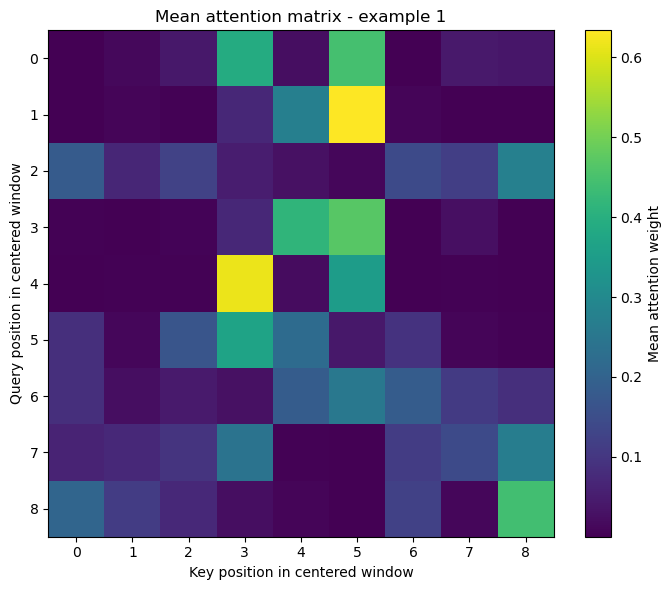

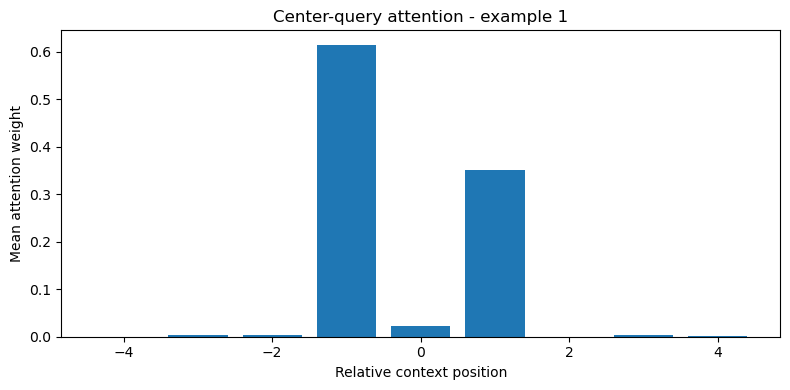

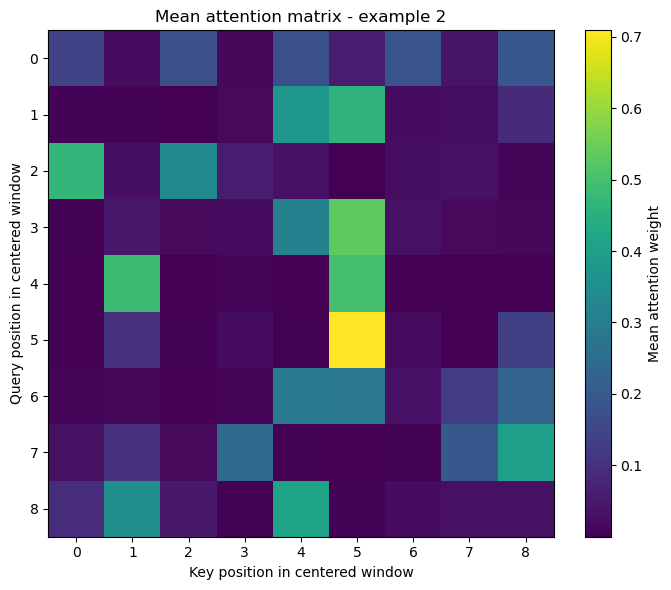

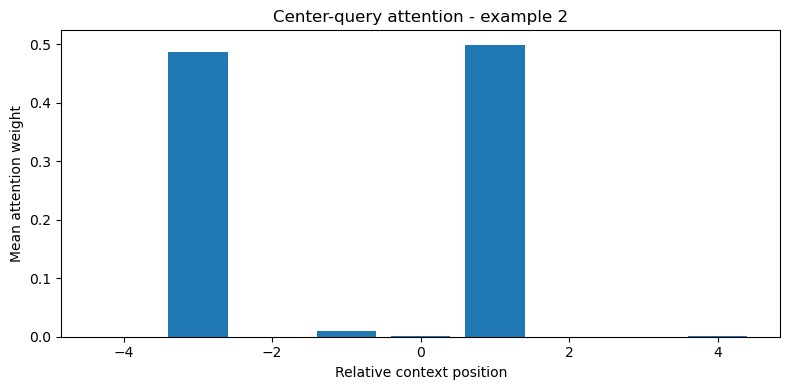

 example  position  observed_symbol_index  true_source_token_id  predicted_source_token_id  confidence                                                                                             selection_reason
       1      4411                   2972                    76                         76    0.984728 same ambiguous observed symbol; different underlying values; different predictions; both predictions correct
       2      4010                   2972                  1697                       1697    0.906299 same ambiguous observed symbol; different underlying values; different predictions; both predictions correct


In [14]:
analysis_checkpoint = (
    MODEL_DIR
    / "attention_ambiguous_anchors_20.pt"
)

analysis_model, _ = (
    build_ambiguous_model(
        analysis_checkpoint
    )
)

example_records = []

offsets = np.arange(
    -selected_radius,
    selected_radius + 1,
)

for example_index, center in enumerate(
    selected_example_positions,
    start=1,
):
    window = test_observed[
        center-selected_radius:
        center+selected_radius+1
    ]

    tensor = torch.as_tensor(
        window[None, :],
        dtype=torch.long,
        device=DEVICE,
    )

    with torch.no_grad():
        logits, layer_weights = (
            analysis_model(
                tensor,
                return_attention=True,
            )
        )

        probabilities = torch.softmax(
            logits,
            dim=1,
        )[0]

    predicted_index = int(
        probabilities.argmax().item()
    )

    predicted_source = (
        index_to_source[
            predicted_index
        ]
    )

    final_layer = (
        layer_weights[-1][
            0
        ]
        .cpu()
        .numpy()
    )

    # Average across heads for visualization.
    mean_matrix = final_layer.mean(
        axis=0
    )

    center_profile = mean_matrix[
        selected_radius
    ]

    example_records.append({
        "example": example_index,
        "position": center,
        "observed_symbol_index": int(
            test_observed[center]
        ),
        "true_source_token_id": (
            test_true_raw_source[
                center
            ]
        ),
        "predicted_source_token_id": (
            predicted_source
        ),
        "confidence": float(
            probabilities[
                predicted_index
            ].item()
        ),
        "selection_reason": (
            selection_reason
        ),
    })

    plt.figure(
        figsize=(7, 6)
    )

    plt.imshow(
        mean_matrix,
        aspect="auto",
        origin="upper",
    )

    plt.xlabel(
        "Key position in centered window"
    )

    plt.ylabel(
        "Query position in centered window"
    )

    plt.title(
        f"Mean attention matrix - example {example_index}"
    )

    plt.colorbar(
        label="Mean attention weight"
    )

    plt.tight_layout()

    matrix_path = (
        RESULT_DIR
        / (
            f"task8_attention_matrix_"
            f"example_{example_index}.png"
        )
    )

    plt.savefig(
        matrix_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    plt.figure(
        figsize=(8, 4)
    )

    plt.bar(
        offsets,
        center_profile,
    )

    plt.xlabel(
        "Relative context position"
    )

    plt.ylabel(
        "Mean attention weight"
    )

    plt.title(
        f"Center-query attention - example {example_index}"
    )

    plt.tight_layout()

    profile_path = (
        RESULT_DIR
        / (
            f"task8_attention_profile_"
            f"example_{example_index}.png"
        )
    )

    plt.savefig(
        profile_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()


examples_frame = pd.DataFrame(
    example_records
)

examples_path = (
    DATA_DIR
    / "task8_selected_attention_examples.csv"
)

examples_frame.to_csv(
    examples_path,
    index=False,
)

print(
    examples_frame.to_string(
        index=False
    )
)

## Aggregate attention-distance and entropy analysis

For the final attention layer and center query, heads are averaged first.

Expected absolute context distance is

$$
D_i
=
\sum_{r=-m}^{m}
A_i(r)|r|.
$$

Attention entropy is

$$
H_i
=
-\sum_r
A_i(r)\log A_i(r).
$$

These statistics are compared for:

- ambiguous vs unambiguous centers;
- correct vs incorrect decodings.

They provide aggregate context rather than relying only on two illustrations.

In [15]:
dummy_labels = np.zeros(
    len(test_observed),
    dtype=np.int64,
)

analysis_dataset = CenteredWindowDataset(
    test_observed,
    dummy_labels,
    radius=selected_radius,
    centers=test_common_positions,
)

analysis_loader = DataLoader(
    analysis_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

attention_stat_rows = []

with torch.no_grad():
    for windows, _, centers_batch in analysis_loader:
        windows_device = windows.to(
            DEVICE
        )

        logits, layer_weights = (
            analysis_model(
                windows_device,
                return_attention=True,
            )
        )

        probabilities = torch.softmax(
            logits,
            dim=1,
        )

        predictions = probabilities.argmax(
            dim=1
        ).cpu().numpy()

        final_weights = (
            layer_weights[-1]
            .cpu()
            .numpy()
        )

        # Shape:
        # batch x heads x query x key.
        center_weights = (
            final_weights[
                :,
                :,
                selected_radius,
                :,
            ]
            .mean(axis=1)
        )

        safe_weights = np.clip(
            center_weights,
            1e-12,
            1.0,
        )

        expected_distance = (
            center_weights
            * np.abs(
                offsets
            )[None, :]
        ).sum(axis=1)

        entropy = -(
            safe_weights
            * np.log(
                safe_weights
            )
        ).sum(axis=1)

        for row_index, center in enumerate(
            centers_batch.numpy()
        ):
            original_glyph = (
                test_raw[
                    center
                ]
            )

            truth_index = (
                source_to_index[
                    test_true_raw_source[
                        center
                    ]
                ]
            )

            attention_stat_rows.append({
                "position": int(center),
                "ambiguous_occurrence": (
                    original_glyph
                    in merged_original_glyphs
                ),
                "correct": (
                    int(
                        predictions[
                            row_index
                        ]
                    )
                    == truth_index
                ),
                "expected_absolute_attention_distance": float(
                    expected_distance[
                        row_index
                    ]
                ),
                "attention_entropy": float(
                    entropy[
                        row_index
                    ]
                ),
            })


attention_stats = pd.DataFrame(
    attention_stat_rows
)

attention_stats_path = (
    DATA_DIR
    / "task8_attention_aggregate_statistics.csv"
)

attention_stats.to_csv(
    attention_stats_path,
    index=False,
)

attention_summary = (
    attention_stats
    .groupby(
        [
            "ambiguous_occurrence",
            "correct",
        ]
    )
    [
        [
            "expected_absolute_attention_distance",
            "attention_entropy",
        ]
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
            "std",
        ]
    )
)

summary_path = (
    DATA_DIR
    / "task8_attention_aggregate_summary.csv"
)

attention_summary.to_csv(
    summary_path
)

print(attention_summary)

                             expected_absolute_attention_distance            \
                                                            count      mean   
ambiguous_occurrence correct                                                  
False                False                                   5393  0.776351   
                     True                                     615  0.948363   
True                 False                                   3424  1.120431   
                     True                                    2125  1.157344   

                                                 attention_entropy            \
                                median       std             count      mean   
ambiguous_occurrence correct                                                   
False                False    0.735272  0.415669              5393  1.225711   
                     True     0.867479  0.551859               615  1.306282   
True                 False    1.043637  0.3938

# Steps 7-8 outputs

### Controlled ambiguity

- `task7_anchor_signature_summary.csv`
- `task7_merge_pairs.csv`
- `task7_ambiguous_training_manifest.csv`
- `task7_ambiguous_decoder_comparison.csv`
- per-model ambiguous predictions;
- per-model relation-recovery tables;
- `task7_attention_advantage_bijective_vs_ambiguous.csv`

### Attention interpretation

- `task8_selected_attention_examples.csv`
- `task8_attention_aggregate_statistics.csv`
- `task8_attention_aggregate_summary.csv`
- attention matrices and center-query profiles for reproducibly selected same-symbol examples.

The next notebook asks an LLM to interpret these fixed attention patterns **before** revealing context-intervention results.